In [2]:
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler


In [50]:
#FOR CSV
# re opening the xflare instances time series collection files
#dataframe
xflareinstances_reloaded = pd.read_csv("/kaggle/input/datasets/izzysbn/partition1-swanrafal-et-al/partition1/753.csv", sep = "\t")
#converting the json formatted strings into python list (.loads) into a numpy array (.array) and finally does it on all elements in the input/output (.apply)
#xflareinstances_reloaded["input"/"output"] is a pandas series 

#inputxflareinstances = xflareinstances_reloaded["input"].apply(lambda x: np.array(json.loads(x)))
#outputxflareinstances = xflareinstances_reloaded["output"].apply(lambda x: np.array(json.loads(x)))

#stack into a 3d array for lstm use
#.to_numpy makes it a 1d array array([array[], array[], ...]), N separate arrays of (L, F)
#.stack makes it (N, L, F), adds another dimension into a 3d array!!!!
#X = np.stack(inputxflareinstances.to_numpy())
#Y = np.stack(outputxflareinstances.to_numpy()) 

#print(X.shape)
#print(Y.shape)
print(xflareinstances_reloaded.shape)
xflareinstances_reloaded.columns.tolist()

(1716, 55)


['Timestamp',
 'TOTUSJH',
 'TOTBSQ',
 'TOTPOT',
 'TOTUSJZ',
 'ABSNJZH',
 'SAVNCPP',
 'USFLUX',
 'TOTFZ',
 'MEANPOT',
 'EPSZ',
 'MEANSHR',
 'SHRGT45',
 'MEANGAM',
 'MEANGBT',
 'MEANGBZ',
 'MEANGBH',
 'MEANJZH',
 'TOTFY',
 'MEANJZD',
 'MEANALP',
 'TOTFX',
 'EPSY',
 'EPSX',
 'R_VALUE',
 'CRVAL1',
 'CRLN_OBS',
 'CRLT_OBS',
 'CRVAL2',
 'HC_ANGLE',
 'SPEI',
 'LAT_MIN',
 'LON_MIN',
 'LAT_MAX',
 'LON_MAX',
 'QUALITY',
 'BFLARE',
 'BFLARE_LABEL',
 'CFLARE',
 'CFLARE_LABEL',
 'MFLARE',
 'MFLARE_LABEL',
 'XFLARE',
 'XFLARE_LABEL',
 'BFLARE_LOC',
 'BFLARE_LABEL_LOC',
 'CFLARE_LOC',
 'CFLARE_LABEL_LOC',
 'MFLARE_LOC',
 'MFLARE_LABEL_LOC',
 'XFLARE_LOC',
 'XFLARE_LABEL_LOC',
 'XR_MAX',
 'XR_QUAL',
 'IS_TMFI']

In [51]:
#only getting the x-ray flux
#X = X[:, :, 5:6]
#X.shape

xflux_only_fullar = xflareinstances_reloaded.iloc[:, 52]
xflux_only_fullar

0       8.412600e-07
1       9.302700e-07
2       7.406800e-07
3       6.338500e-07
4       6.299600e-07
            ...     
1711    7.879500e-07
1712    1.187400e-06
1713    8.151200e-07
1714    5.092700e-07
1715    6.352000e-07
Name: XR_MAX, Length: 1716, dtype: float64

In [52]:
#convert df to numpy array
np_xflux = xflux_only_fullar.to_numpy()
np_xflux

array([8.4126e-07, 9.3027e-07, 7.4068e-07, ..., 8.1512e-07, 5.0927e-07,
       6.3520e-07])

In [53]:
#number of features
F = 1


#NEW LOG SCALER
#clip replaces all the negative values with 0, fine because no negatives
#computes log(1 + z), handles zeros and small values better than plain log
#same shape is maintained
X_log = np.log1p(np.clip(np_xflux, 0, None))

# 2. Scale features
#creating a scaler on the training section of the data -> using the logged version
#reshapes the dataset to be (rows*time steps, feature) cause time series doesn't work on scaling
x_scaler = StandardScaler().fit(X_log.reshape(-1, F))

#implementing this scaler onto both the training and validation datasets
#avoids leakage, only has information on the training sets
#the dataset is re-reshaped into its original (n, l, f) form after it is scaled
X_s = x_scaler.transform(X_log.reshape(-1, F)).reshape(X_log.shape)


# 3. Log + scale targets
#doing basically the same thing but on the Y dataset
#Y_log = np.log1p(np.clip(Y, 0, None))

#y_scaler = StandardScaler().fit(Y_log.reshape(-1,1))
#Y_s = y_scaler.transform(Y_log.reshape(-1,1)).reshape(Y_log.shape)

In [54]:
X_s

array([-0.06019808, -0.05612181, -0.06480421, ..., -0.06139518,
       -0.07540177, -0.06963473])

In [16]:
#Y_s[0]

array([[ 0.46868657],
       [ 1.469754  ],
       [ 0.10329244],
       [-0.60249819],
       [-0.89086789]])

In [30]:
#instance_scaled = np.concatenate((X_s, Y_s[0]))
#instance = np.concatenate((X[0], Y[0]))
#instance_scaled

array([[-0.22344765],
       [-0.22731568],
       [-0.220202  ],
       [-0.21255715],
       [-0.21210736],
       [-0.18202128],
       [-0.19184564],
       [-0.21119521],
       [-0.22117858],
       [-0.18142713],
       [-0.19959886],
       [-0.2064734 ],
       [-0.2170844 ],
       [-0.22210767],
       [-0.21349649],
       [ 0.46868657],
       [ 1.469754  ],
       [ 0.10329244],
       [-0.60249819],
       [-0.89086789]])

In [55]:
# time series
x = X_s                      # shape (N,)
dt = 720.0                      # sampling interval in seconds (GOES 12 min data)

N = len(x)

# FFT
fft = np.fft.fft(x)

# frequency axis
freq = np.fft.fftfreq(N, d=dt)

# power spectrum
power = np.abs(fft)**2


In [56]:
mask = freq > 0
freq_pos = freq[mask]
power_pos = power[mask]

In [57]:
#period cutoff in seconds
T = 7200.0
#frequency cuttoff in Hz
f_cut = 1.0 / T

# copy spectrum
X_filt = fft.copy()

# zero out high frequencies
X_filt[np.abs(freq) > f_cut] = 0.0

# inverse FFT
x_filtered = np.fft.ifft(X_filt).real

x_filtered

array([-0.14768004, -0.20033979, -0.2061079 , ...,  0.06370665,
        0.01261398, -0.06721071])

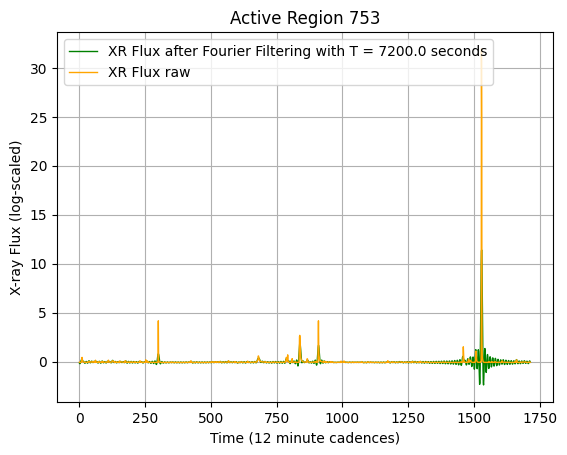

In [58]:
plt.plot( x_filtered,color="green", lw=1, label="XR Flux after Fourier Filtering with T = " + str(T) + " seconds")
plt.plot( X_s,color="orange", lw=1, label="XR Flux raw")
plt.xlabel("Time (12 minute cadences)")
plt.ylabel("X-ray Flux (log-scaled)")
plt.title("Active Region 753")
plt.grid()
plt.legend(loc="upper left")



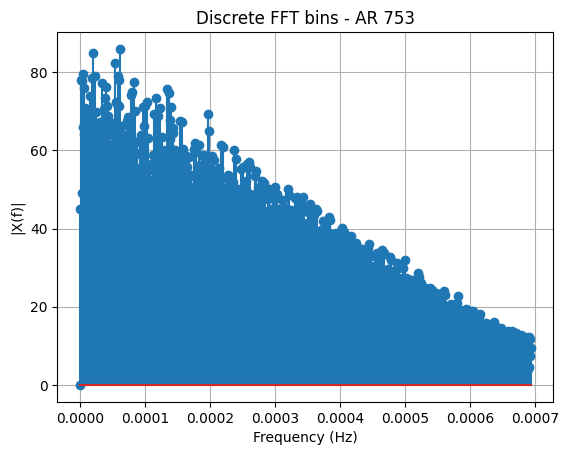

In [60]:
plt.stem(freq[freq >= 0], np.abs(fft[freq >= 0]))
plt.xlabel("Frequency (Hz)")
plt.ylabel("|X(f)|") #represents the strength of the frequency: encodes amplitude + phase of frequency bin
plt.title("Discrete FFT bins - AR 753")
plt.grid()


In [40]:
freq < 1/3000

array([ True,  True,  True, ...,  True,  True,  True])

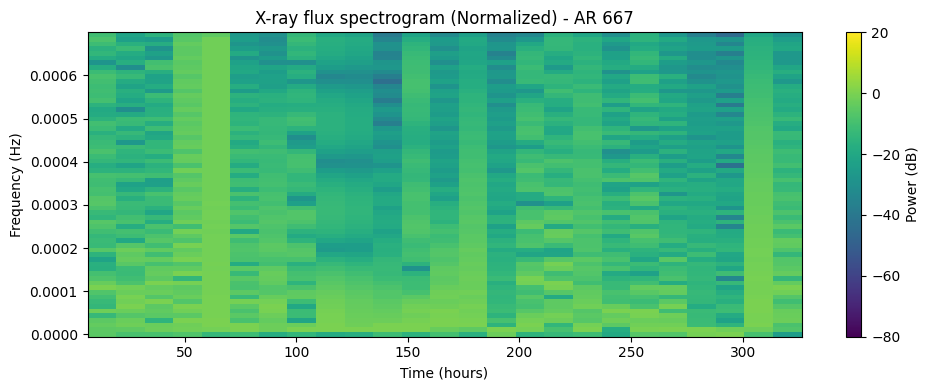

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

def plot_spectrogram(x, fs, nperseg=256, noverlap=None, detrend="constant",
                     scaling="density", mode="psd", log_scale=True,
                     fmax=None, tmax=None, title="Spectrogram"):
    """
    x: 1D signal
    fs: sampling frequency in Hz (fs = 1/dt)
    """
    if noverlap is None:
        noverlap = nperseg // 2

    f, t, Sxx = spectrogram(
        x,
        fs=fs,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        detrend=detrend,
        scaling=scaling,
        mode=mode
    )

    # Convert to log scale for visibility
    if log_scale:
        # avoid log(0)
        Splot = 10 * np.log10(Sxx + 1e-12)
        ylabel = "Power (dB)"
    else:
        Splot = Sxx
        ylabel = "Power"

    # Optional limits
    if fmax is not None:
        keep = f <= fmax
        f = f[keep]
        Splot = Splot[keep, :]

    if tmax is not None:
        keep = t <= tmax
        t = t[keep]
        Splot = Splot[:, keep]
    S_norm = Splot - np.max(Splot, axis=0, keepdims=True)
    plt.figure(figsize=(10, 4))
    t_plot = t / 3600  # hours
    plt.pcolormesh(t_plot, f, S_norm, shading="auto", vmin=-80, vmax=20)
    plt.ylabel("Frequency (Hz)")
    plt.xlabel("Time (hours)")
    plt.title(title)
    plt.colorbar(label=ylabel)
    plt.tight_layout()
    plt.show()

# ---- Example usage ----
# x = your 1D numpy array
# dt = seconds per sample
# fs = 1.0 / dt
plot_spectrogram(
    np_xflux,
    fs=1.0/720.0,      # 12 minutes per sample
    nperseg=128,       # indices per window
    fmax=0.01,       # up to ~0.00056 Hz (period >= 30 min)
    title="X-ray flux spectrogram (Normalized) - AR 667"
)

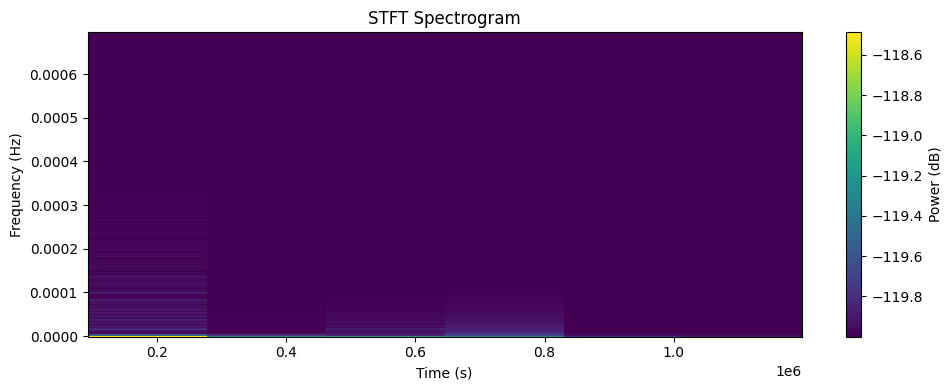

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft

def plot_stft(x, fs, nperseg=256, noverlap=None, log_scale=True, fmax=None, title="STFT Spectrogram"):
    if noverlap is None:
        noverlap = nperseg // 2

    f, t, Zxx = stft(x, fs=fs, window="hann", nperseg=nperseg, noverlap=noverlap, boundary=None)
    S = np.abs(Zxx)**2  # power

    if log_scale:
        S = 10 * np.log10(S + 1e-12)
        cbar = "Power (dB)"
    else:
        cbar = "Power"

    if fmax is not None:
        keep = f <= fmax
        f = f[keep]
        S = S[keep, :]

    plt.figure(figsize=(10, 4))
    plt.pcolormesh(t, f, S, shading="auto")
    plt.ylabel("Frequency (Hz)")
    plt.xlabel("Time (s)")
    plt.title(title)
    plt.colorbar(label=cbar)
    plt.tight_layout()
    plt.show()

# Example:
plot_stft(np_xflux, fs=1/720.0, nperseg=512, fmax=0.01)